# PM2.5 by hour of the day: Mumbai and Bengaluru (2023)

In this notebook, we show the hourly PM2.5 of 2023 at two CPCB stations: Powai in
Mumbai, and Silk Board, a busy traffic junction in Bengaluru. We use
`plot_aqi_radial_hourly`, which draws each hour on a 24-hour clock in IST.

In [1]:
from vayuayan import CPCBHistorical, plot_aqi_radial_hourly, set_theme, sub_index

set_theme()

## Download the data

We download the raw 15-minute values with `raw_readings`. CPCB times are in IST.

In [2]:
raw = CPCBHistorical().raw_readings(["site_5112", "site_1558"], 2023, ["PM2.5"])
raw["station_name"].value_counts()

station_name
Powai, Mumbai - MPCB             32565
Silk Board, Bengaluru - KSPCB    31286
Name: count, dtype: int64

## Calculate the hourly sub-index

We take the mean of each hour and convert it to the CPCB PM2.5 sub-index with
`sub_index`. CPCB defines the sub-index for a 24-hour mean, so the hourly value is not
an official AQI. It puts each hour on the AQI category scale.

In [3]:
hourly = (
    raw.assign(timestamp=raw["timestamp"].dt.floor("h"))
    .groupby(["station_name", "timestamp"], as_index=False)["value"]
    .mean()
)
hourly["value"] = [sub_index("PM2.5", c) for c in hourly["value"]]
hourly["city"] = hourly["station_name"].str.replace(r" - .*", "", regex=True)
hourly.head()

,station_name,timestamp,value,city
0,"Powai, Mumbai - MPCB",2023-01-01 00:00:00,87.585259,"Powai, Mumbai"
1,"Powai, Mumbai - MPCB",2023-01-01 01:00:00,119.093103,"Powai, Mumbai"
2,"Powai, Mumbai - MPCB",2023-01-01 02:00:00,306.744302,"Powai, Mumbai"
3,"Powai, Mumbai - MPCB",2023-01-01 03:00:00,200.765000,"Powai, Mumbai"
4,"Powai, Mumbai - MPCB",2023-01-01 04:00:00,195.587672,"Powai, Mumbai"


## Show the daily cycle in each month

By default, each ring is a month, with January at the centre and midnight at the top.

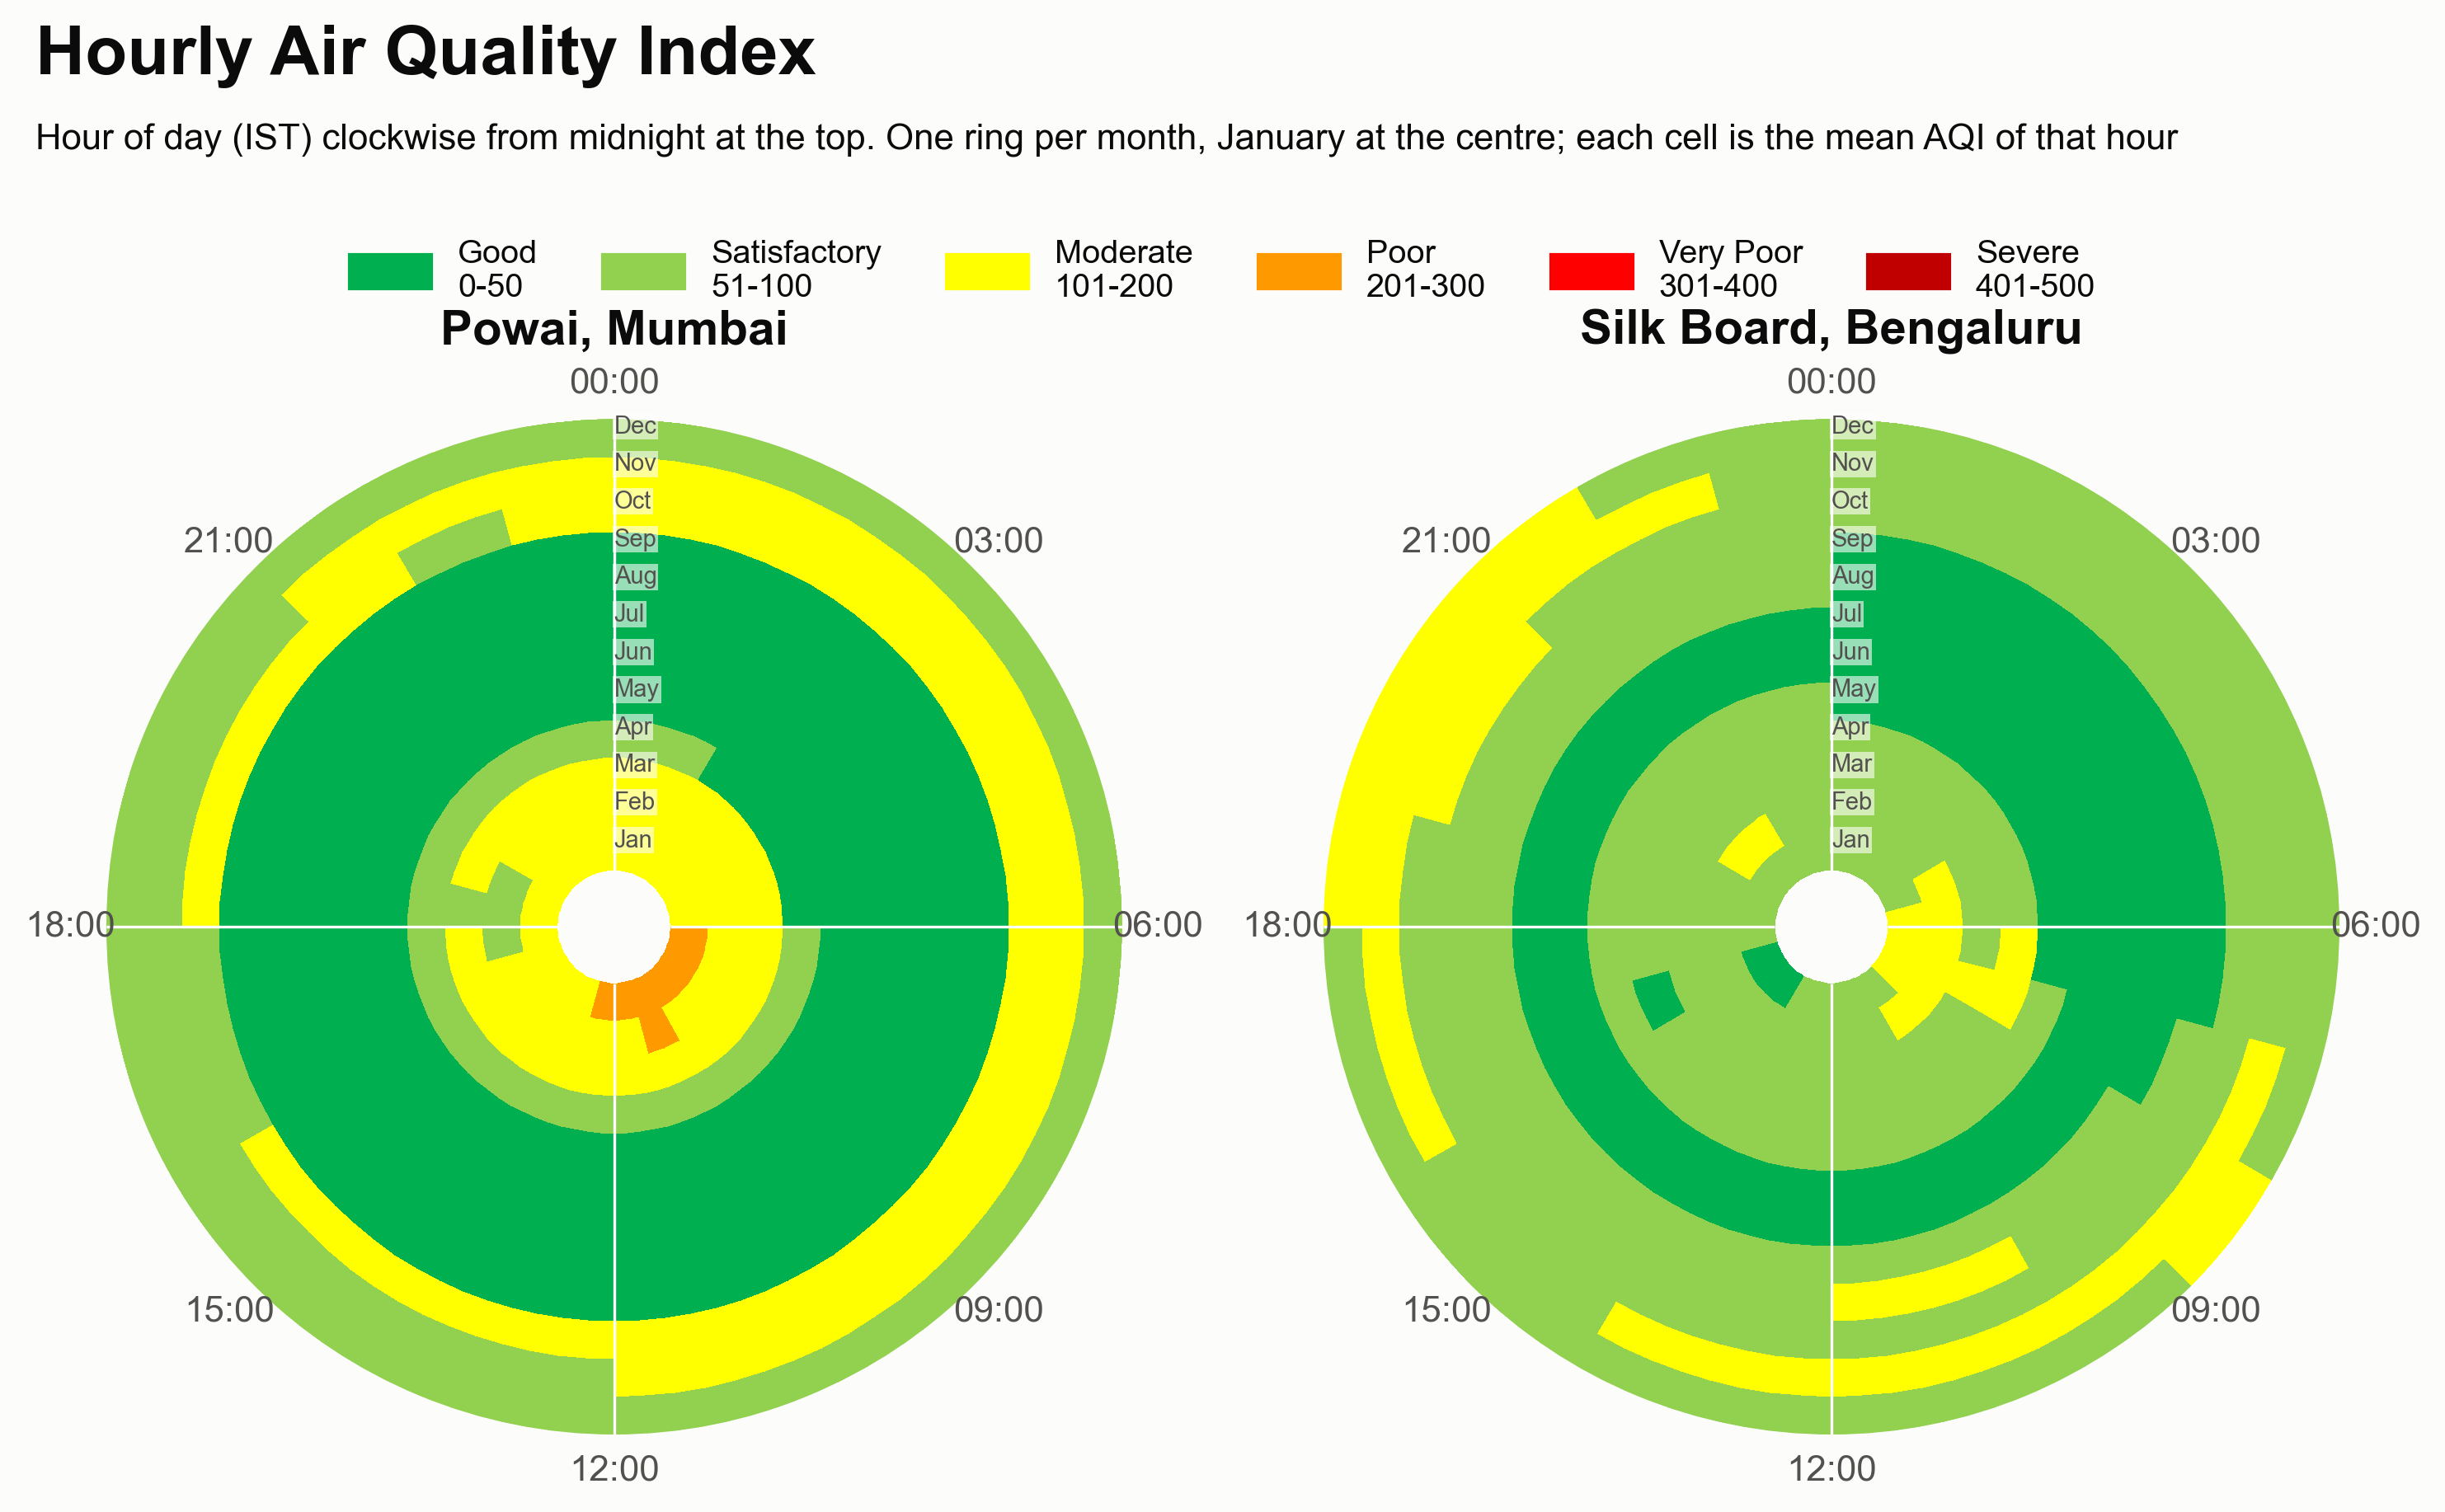

In [4]:
plot_aqi_radial_hourly(hourly)

Powai is cleanest from May to September, when every hour is Good. In winter it peaks at
09:00 to 10:00, when morning traffic adds to the shallow night-time air layer; in
January, 06:00 to 12:00 is Poor. Silk Board changes less with the season and is Good at
every hour only in June and July. Its winter day has two peaks, 64 to 65 µg/m³ at 07:00
to 08:00 and 61 µg/m³ at 20:00, against 34 µg/m³ at 14:00 to 15:00. The peaks match the morning and evening traffic at the junction.

## Show one ring for each day

Set `rings="day"` for one ring per date. Short events become visible, such as Diwali on
12 November 2023.

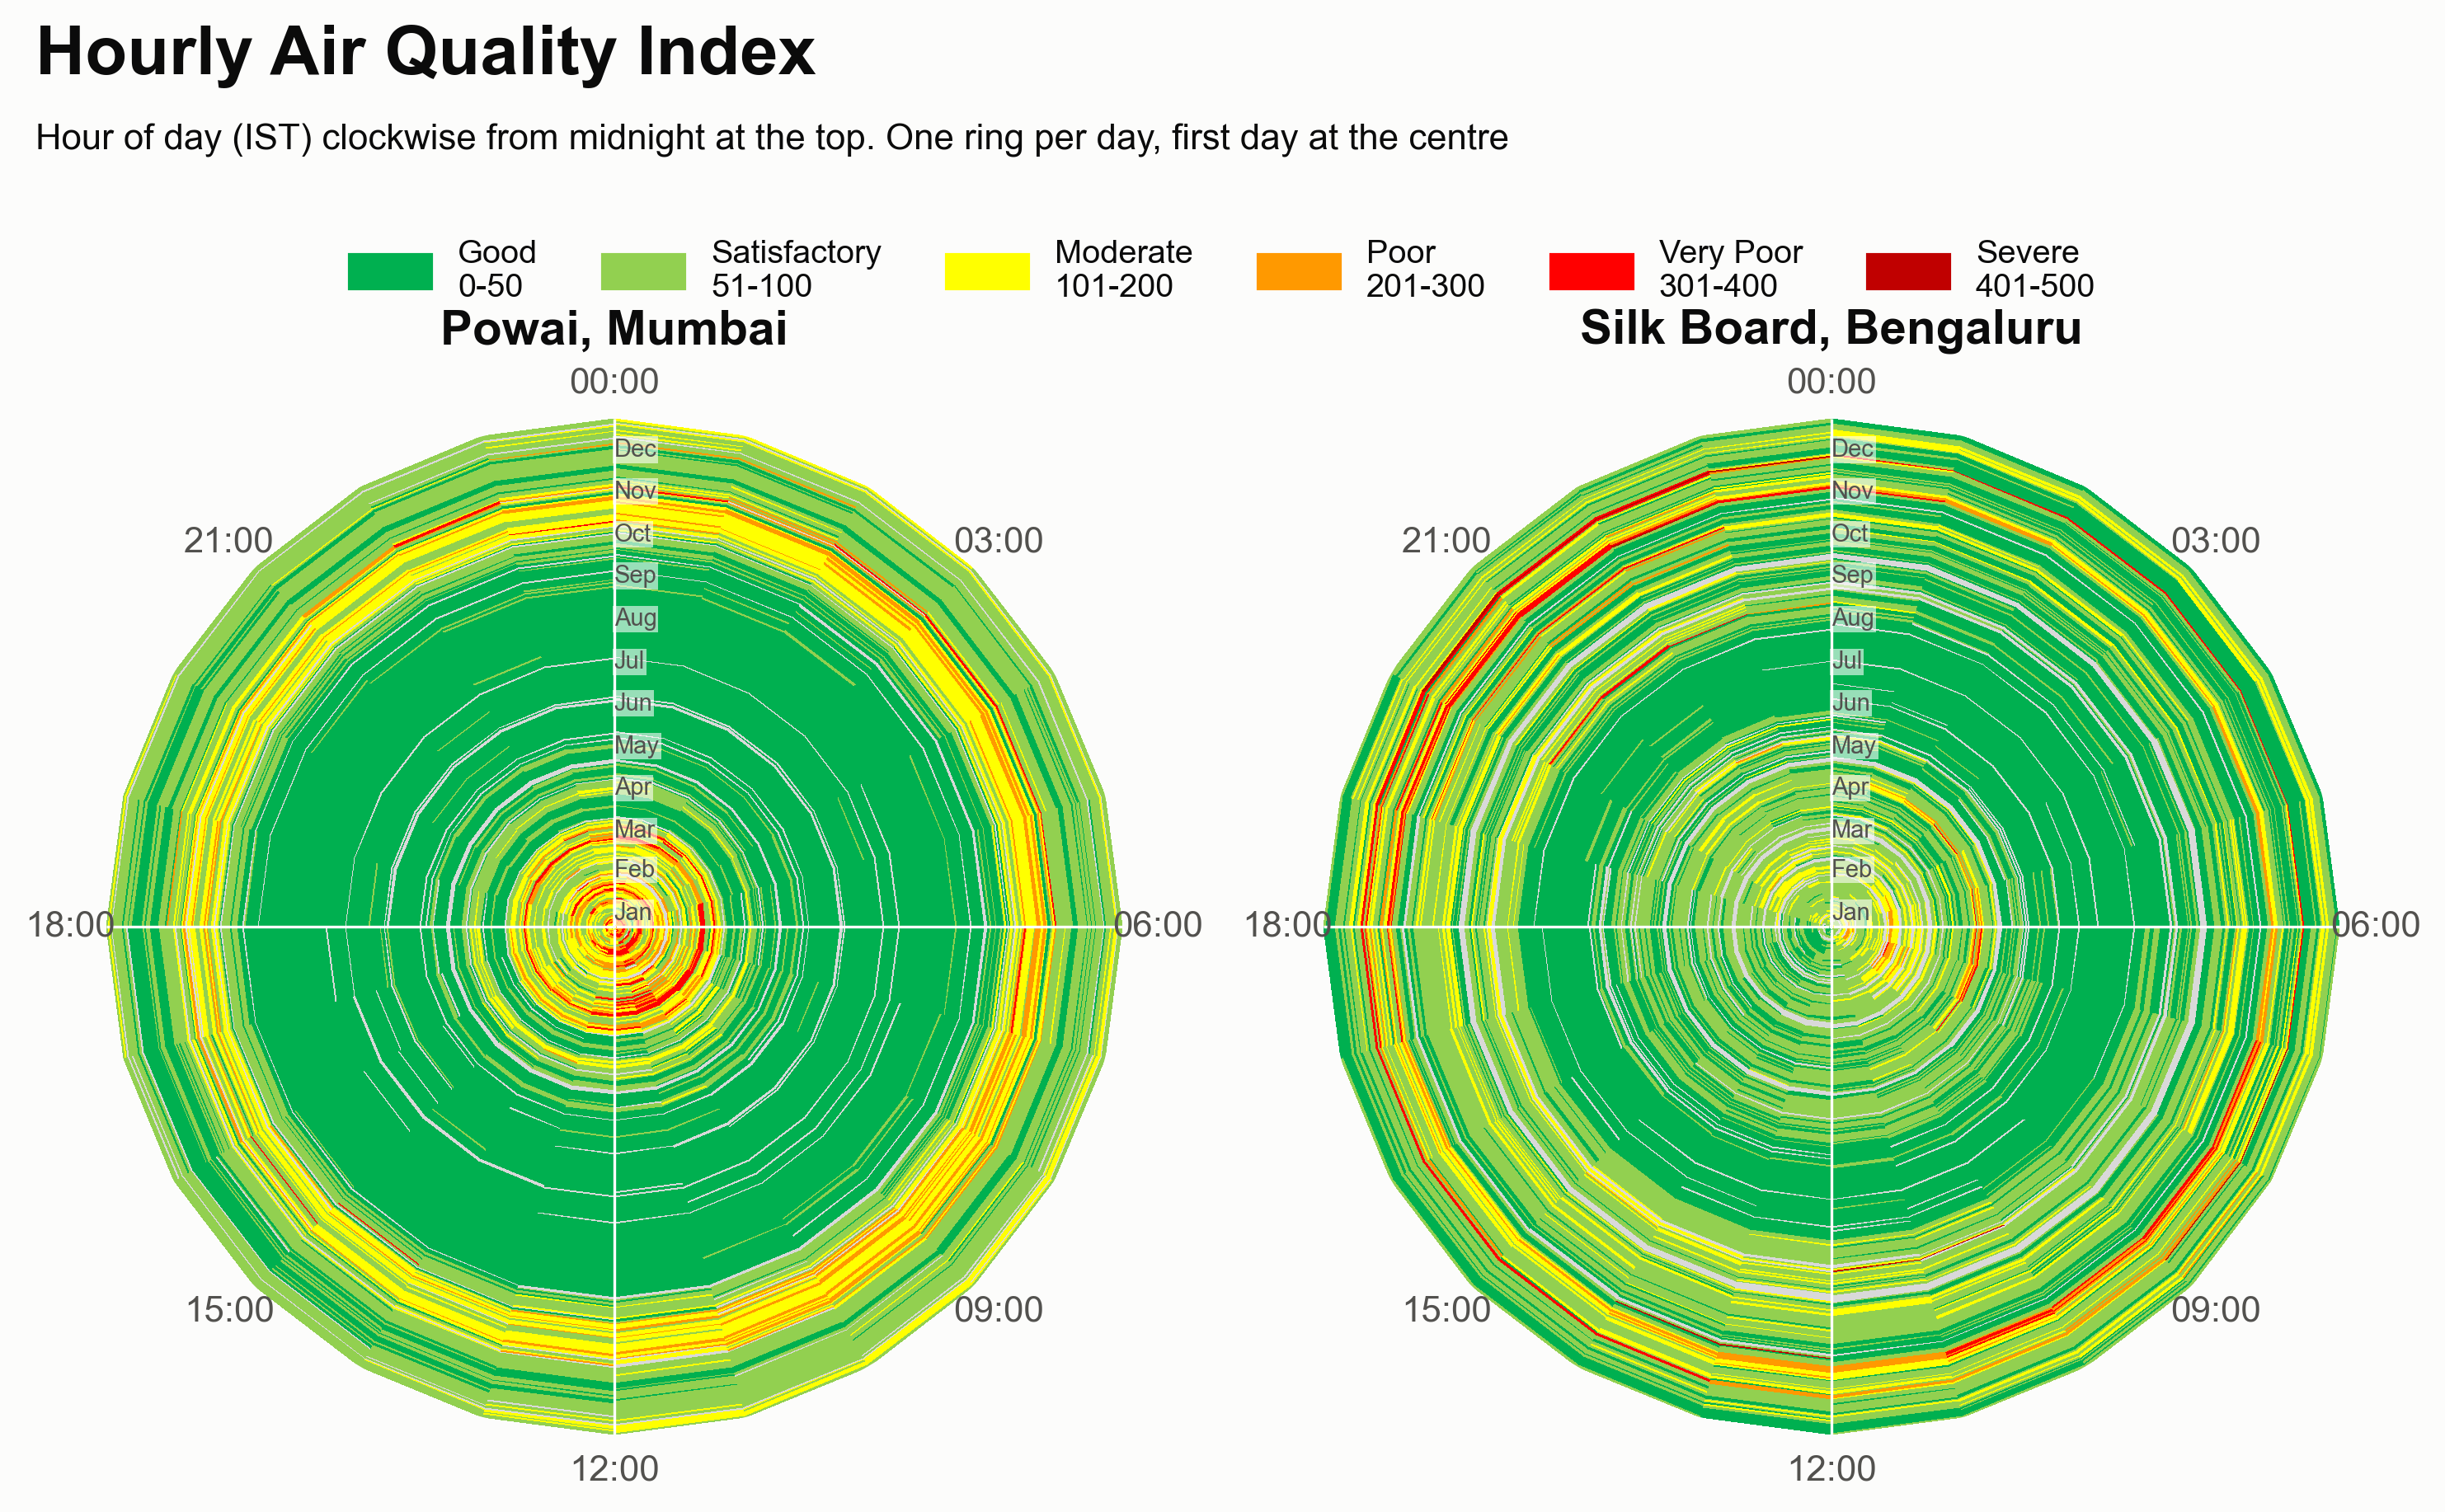

In [5]:
plot_aqi_radial_hourly(hourly, rings="day")

At both stations, the night-time PM2.5 rose from 21 to 50 µg/m³ on 8 to 10 November to
104 to 152 µg/m³ on 12 and 13 November.